# Final Project
## Which routes generate the highest revenue efficiency?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

yellow = pd.read_parquet("yellow_tripdata_2026-05.parquet")
uberlyft = pd.read_parquet("fhvhv_tripdata_2026-05.parquet")

yellow.info()
uberlyft.info()

<class 'pandas.DataFrame'>
RangeIndex: 4090836 entries, 0 to 4090835
Data columns (total 20 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   VendorID               int32         
 1   tpep_pickup_datetime   datetime64[us]
 2   tpep_dropoff_datetime  datetime64[us]
 3   passenger_count        float64       
 4   trip_distance          float64       
 5   RatecodeID             float64       
 6   store_and_fwd_flag     str           
 7   PULocationID           int32         
 8   DOLocationID           int32         
 9   payment_type           int64         
 10  fare_amount            float64       
 11  extra                  float64       
 12  mta_tax                float64       
 13  tip_amount             float64       
 14  tolls_amount           float64       
 15  improvement_surcharge  float64       
 16  total_amount           float64       
 17  congestion_surcharge   float64       
 18  Airport_fee            float64   

## Part A. Do different routes show meaningful differences in revenue efficiency?

### 1. Data Cleaning

In [2]:
# Calculate trip duration in minutes
yellow['trip_minutes'] = (
    yellow['tpep_dropoff_datetime'] -
    yellow['tpep_pickup_datetime']
).dt.total_seconds() / 60

# Filter invalid trips
yellow_clean = yellow[
    (yellow['trip_minutes'] > 0) &
    (yellow['trip_distance'] > 0) &
    (yellow['fare_amount'] > 0) &
    (yellow['PULocationID'].notna()) &
    (yellow['DOLocationID'].notna())
].copy()

print("Original trips:", len(yellow))
print("Valid trips:", len(yellow_clean))

Original trips: 4090836
Valid trips: 3911886


### 2. Calculate Revenue Efficiency by Route

In [3]:
# Aggregate data by route
routes = (
    yellow_clean
    .groupby(['PULocationID', 'DOLocationID'])
    .agg(
        trip_count=('fare_amount', 'size'),
        total_fare=('fare_amount', 'sum'),
        total_distance=('trip_distance', 'sum'),
        total_minutes=('trip_minutes', 'sum')
    )
    .reset_index()
)

# Calculate revenue efficiency
routes['fare_per_minute'] = (
    routes['total_fare'] / routes['total_minutes']
)

routes['fare_per_mile'] = (
    routes['total_fare'] / routes['total_distance']
)

# Remove routes with insufficient observations
routes = routes[routes['trip_count'] >= 100].copy()

routes.head()

,PULocationID,DOLocationID,trip_count,total_fare,total_distance,total_minutes,fare_per_minute,fare_per_mile
133,4,4,178,2088.97,105.29,810.566667,2.577172,19.840156
139,4,13,158,3295.97,616.97,2226.766667,1.480160,5.342188
155,4,33,101,2010.16,451.51,1665.783333,1.206736,4.452083
162,4,41,125,4237.71,955.01,5172.766667,0.819235,4.437346
163,4,42,128,4189.59,991.30,3662.483333,1.143921,4.226359


### 3. Distribution of Revenue Efficiency

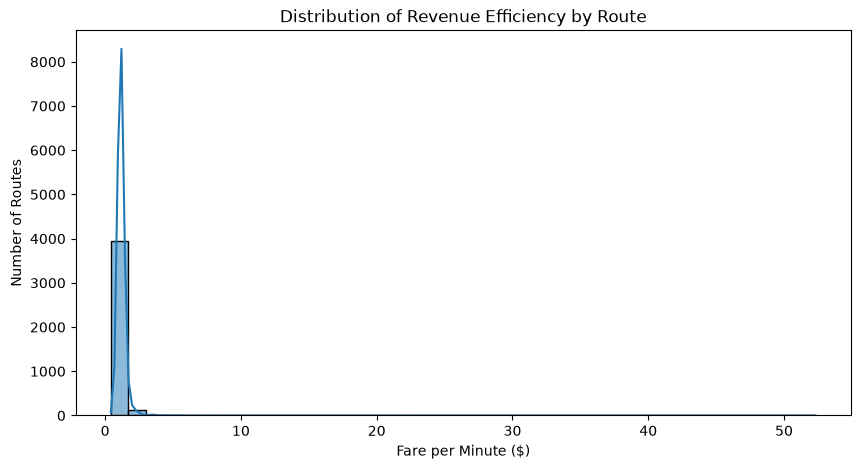

In [4]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=routes,
    x='fare_per_minute',
    bins=40,
    kde=True
)

plt.title('Distribution of Revenue Efficiency by Route')
plt.xlabel('Fare per Minute ($)')
plt.ylabel('Number of Routes')

plt.show()

The distribution of revenue efficiency is highly right-skewed, with most routes clustered within a relatively narrow range. This suggests that __most routes generate relatively similar revenue per minute__. Therefore, __revenue efficiency alone may not be sufficient to identify attractive business opportunities__. Additional factors, such as trip volume, should be considered to evaluate market potential.

### 4. Top 10 Most Efficient Route

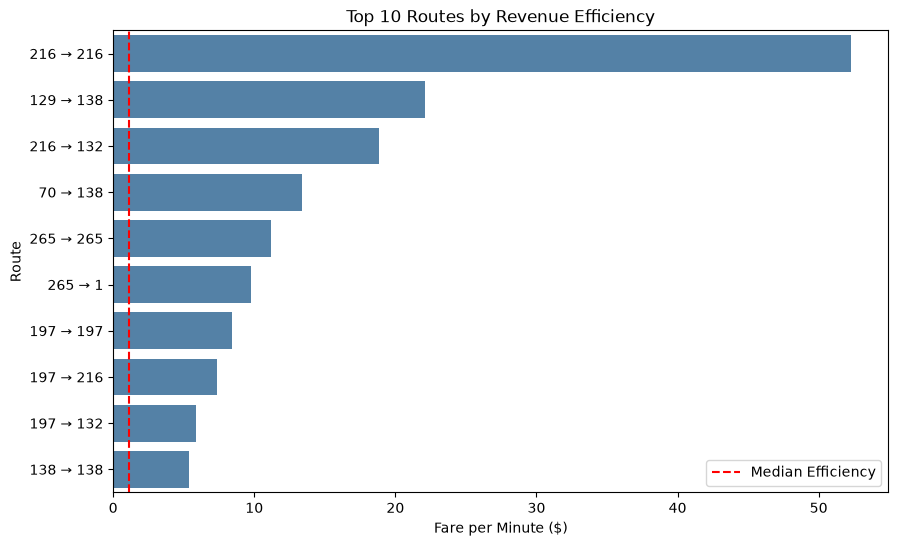

In [5]:
top10 = routes.nlargest(10, 'fare_per_minute').copy()

top10['route'] = (
    top10['PULocationID'].astype(str) +
    ' → ' +
    top10['DOLocationID'].astype(str)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top10,
    x='fare_per_minute',
    y='route',
    color='steelblue'
)

plt.axvline(
    routes['fare_per_minute'].median(),
    color='red',
    linestyle='--',
    label='Median Efficiency'
)

plt.title('Top 10 Routes by Revenue Efficiency')
plt.xlabel('Fare per Minute ($)')
plt.ylabel('Route')

plt.legend()
plt.show()

The top 10 routes show substantially higher revenue efficiency than the median route. For example, Route 216 → 216 generates approximately $52.31 per minute, despite having an average trip duration of only 1.36 minutes and an average distance of 0.26 miles.

This unusually high value suggests that short trip durations or unusual fares may distort the efficiency ranking. Therefore, additional data validation is necessary before treating these routes as attractive business opportunities.

In [6]:
top10 = routes.nlargest(10, 'fare_per_minute').copy()

top10['avg_trip_minutes'] = (
    top10['total_minutes'] / top10['trip_count']
)

top10['avg_trip_distance'] = (
    top10['total_distance'] / top10['trip_count']
)

top10['avg_fare'] = (
    top10['total_fare'] / top10['trip_count']
)

top10[
    [
        'PULocationID',
        'DOLocationID',
        'trip_count',
        'avg_trip_minutes',
        'avg_trip_distance',
        'avg_fare',
        'fare_per_minute'
    ]
]

,PULocationID,DOLocationID,trip_count,avg_trip_minutes,avg_trip_distance,avg_fare,fare_per_minute
31860,216,216,526,1.359474,0.263213,71.114163,52.310057
18391,129,138,521,2.896449,1.440345,64.111958,22.134674
31792,216,132,771,4.563878,1.733619,86.007004,18.845158
9787,70,138,211,3.667299,1.079052,49.055024,13.376338
40362,265,265,409,7.010554,3.951369,78.440269,11.188883
40257,265,1,163,10.418814,6.433497,101.731043,9.764167
29463,197,197,103,4.470712,0.751942,37.623204,8.415484
29473,197,216,156,6.276709,1.169295,46.391538,7.391060
29416,197,132,151,14.274393,4.386623,83.682914,5.862450
20071,138,138,1027,8.574521,1.711879,46.249455,5.393824


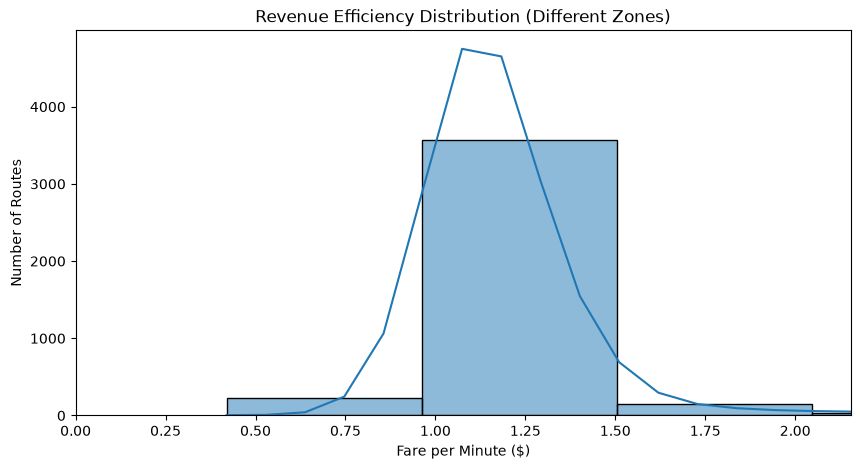

In [7]:
routes_diff = routes[
    routes['PULocationID'] != routes['DOLocationID']
].copy()

plt.figure(figsize=(10, 5))

sns.histplot(
    data=routes_diff,
    x='fare_per_minute',
    bins=40,
    kde=True
)

plt.xlim(
    0,
    routes_diff['fare_per_minute'].quantile(0.99)
)

plt.title('Revenue Efficiency Distribution (Different Zones)')
plt.xlabel('Fare per Minute ($)')
plt.ylabel('Number of Routes')

plt.show()

### 5. Descriptive Statistics

In [8]:
print(routes['fare_per_minute'].describe())

print(
    "90th / 10th Percentile Ratio:",
    routes['fare_per_minute'].quantile(0.9) /
    routes['fare_per_minute'].quantile(0.1)
)

print(
    "Correlation between Trip Volume and Efficiency:",
    routes['trip_count'].corr(routes['fare_per_minute'])
)

count    4080.000000
mean        1.227379
std         1.002809
min         0.419363
25%         1.062770
50%         1.143199
75%         1.249622
max        52.310057
Name: fare_per_minute, dtype: float64
90th / 10th Percentile Ratio: 1.410004126349873
Correlation between Trip Volume and Efficiency: -0.0433925151929164


The 90th-to-10th percentile ratio of 1.41 indicates that revenue efficiency varies across routes, although the differences among most routes are relatively moderate. Additionally, the correlation between trip volume and revenue efficiency is approximately -0.043, indicating almost __no linear relationship__ between these two variables.

This suggests that __high-demand routes are not necessarily the most revenue-efficient__. Therefore, both trip volume and revenue efficiency should be considered when evaluating potential market opportunities.

### Part A Conclusion

The initial analysis shows that most Yellow Taxi routes have relatively similar revenue efficiency, while a few routes exhibit unusually high values that may be influenced by short trip durations or unusual fares. Additionally, the weak correlation between trip volume and revenue efficiency (-0.043) suggests that high demand does not necessarily lead to higher revenue efficiency.

Therefore, the next stage will incorporate Uber and Lyft data to compare route-level demand, revenue efficiency, and Yellow Taxi's market presence. The goal is to identify __high-demand routes with relatively low Yellow Taxi participation__ and evaluate __potential market expansion opportunities__ for Yellow Taxi.

## Part B. Identify Market Opportunity for Yellow Taxi

### 1. Data Cleaning

In [9]:
# Standardize Data

# Yellow Taxi
yellow_data = yellow[
    ['PULocationID', 'DOLocationID',
     'trip_distance', 'trip_minutes', 'fare_amount']
].copy()

yellow_data = yellow_data.rename(columns={
    'trip_distance': 'distance',
    'fare_amount': 'fare'
})

yellow_data['service'] = 'Yellow Taxi'

# Uber and Lyft
hvfhs_data = uberlyft[
    ['hvfhs_license_num', 'PULocationID',
     'DOLocationID', 'trip_miles',
     'trip_time', 'base_passenger_fare']
].copy()

hvfhs_data['service'] = hvfhs_data['hvfhs_license_num'].map({
    'HV0003': 'Uber',
    'HV0005': 'Lyft'
})

hvfhs_data = hvfhs_data.rename(columns={
    'trip_miles': 'distance',
    'base_passenger_fare': 'fare'
})

hvfhs_data['trip_minutes'] = hvfhs_data['trip_time'] / 60

In [10]:
def clean_trips(df):
    df = df.copy()

    df['speed_mph'] = (
        df['distance'] / df['trip_minutes'] * 60
    )

    return df[
        (df['trip_minutes'] >= 1) &
        (df['distance'] > 0) &
        (df['fare'] > 0) &
        (df['speed_mph'] <= 80) &
        (df['service'].notna()) &
        (df['PULocationID'].notna()) &
        (df['DOLocationID'].notna())
    ].copy()

yellow_final = clean_trips(yellow_data)
hvfhs_final = clean_trips(hvfhs_data)

print("Yellow Taxi:", len(yellow_final))
print("Uber/Lyft:", len(hvfhs_final))

Yellow Taxi: 3899629
Uber/Lyft: 22110282


To support cross-service comparison, Yellow Taxi, Uber, and Lyft data were standardized using consistent variable names and cleaning criteria. Trips with invalid fares, distances, durations, or implausible average speeds were excluded.

After cleaning, the dataset contains approximately 3.90 million Yellow Taxi trips and 22.11 million Uber/Lyft trips. These records provide the basis for comparing route-level demand and fare efficiency across services.

### 2. Compare Route Demand and Revenue Efficiency

In [11]:
def route_aggregation(df):
    return (
        df.groupby([
            'service',
            'PULocationID',
            'DOLocationID'
        ])
        .agg(
            trip_count=('fare', 'size'),
            total_fare=('fare', 'sum'),
            total_distance=('distance', 'sum'),
            total_minutes=('trip_minutes', 'sum')
        )
        .reset_index()
    )

yellow_routes = route_aggregation(yellow_final)
hvfhs_routes = route_aggregation(hvfhs_final)

all_routes = pd.concat(
    [yellow_routes, hvfhs_routes],
    ignore_index=True
)

all_routes['fare_per_minute'] = (
    all_routes['total_fare'] /
    all_routes['total_minutes']
)

all_routes['fare_per_mile'] = (
    all_routes['total_fare'] /
    all_routes['total_distance']
)

all_routes.head()

,service,PULocationID,DOLocationID,trip_count,total_fare,total_distance,total_minutes,fare_per_minute,fare_per_mile
0,Yellow Taxi,1,1,8,605.5,8.73,22.000000,27.522727,69.358534
1,Yellow Taxi,1,13,1,53.4,13.17,29.600000,1.804054,4.054670
2,Yellow Taxi,1,48,1,124.5,16.26,97.150000,1.281523,7.656827
3,Yellow Taxi,1,61,1,198.3,24.45,77.766667,2.549936,8.110429
4,Yellow Taxi,1,88,1,79.0,14.83,28.800000,2.743056,5.327040


       service  total_trips    total_fare  total_minutes  fare_per_minute
0         Lyft      6770052  1.820654e+08   1.372098e+08         1.326913
1         Uber     15340230  4.525285e+08   3.160481e+08         1.431834
2  Yellow Taxi      3899629  8.352601e+07   7.475498e+07         1.117330


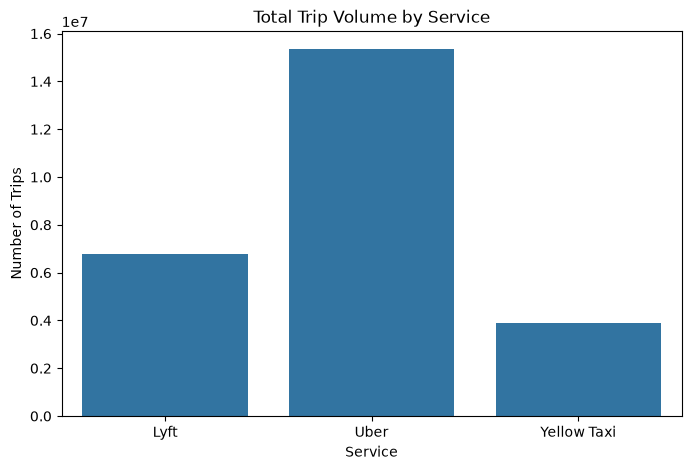

In [12]:
service_summary = (
    all_routes.groupby('service')
    .agg(
        total_trips=('trip_count', 'sum'),
        total_fare=('total_fare', 'sum'),
        total_minutes=('total_minutes', 'sum')
    )
    .reset_index()
)

service_summary['fare_per_minute'] = (
    service_summary['total_fare'] /
    service_summary['total_minutes']
)

print(service_summary)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=service_summary,
    x='service',
    y='total_trips'
)

plt.title('Total Trip Volume by Service')
plt.ylabel('Number of Trips')
plt.xlabel('Service')
plt.show()

In [13]:
# Exclude unknown or undefined taxi zones
all_routes_valid = all_routes[
    (~all_routes['PULocationID'].isin([264, 265])) &
    (~all_routes['DOLocationID'].isin([264, 265]))
].copy()

The comparison shows that Uber has the highest trip volume, with approximately 15.34 million trips, followed by Lyft with 6.77 million and Yellow Taxi with 3.90 million.

Uber also has the highest base-fare revenue efficiency at approximately 1.43 per minute, compared with 1.33 for Lyft and 1.12 for Yellow Taxi. These results indicate differences in observed trip activity and fare efficiency across services.

However, differences in fare structures and operating costs mean that these figures should not be interpreted as direct comparisons of profitability.

### 3. Identify Potential Market Gap

In [14]:
market = all_routes_valid.pivot_table(
    index=['PULocationID', 'DOLocationID'],
    columns='service',
    values='trip_count',
    aggfunc='sum',
    fill_value=0
).reset_index()

market.columns.name = None

for service in ['Yellow Taxi', 'Uber', 'Lyft']:
    if service not in market.columns:
        market[service] = 0

market['rideshare_trips'] = (
    market['Uber'] + market['Lyft']
)

market['total_trips'] = (
    market['Yellow Taxi'] + market['rideshare_trips']
)

market['yellow_share'] = (
    market['Yellow Taxi'] /
    market['total_trips']
)

market['rideshare_share'] = (
    market['rideshare_trips'] /
    market['total_trips']
)

In [15]:
# Focus on routes with meaningful total demand
market_filtered = market[
    market['total_trips'] >= 100
].copy()

demand_threshold = (
    market_filtered['rideshare_trips'].quantile(0.75)
)

# High rideshare demand + low Yellow Taxi presence
opportunities = market_filtered[
    (market_filtered['rideshare_trips'] >= demand_threshold) &
    (market_filtered['yellow_share'] < 0.10)
].copy()

opportunities = opportunities.sort_values(
    'rideshare_trips',
    ascending=False
)

opportunities[
    ['PULocationID', 'DOLocationID',
     'Uber', 'Lyft', 'Yellow Taxi',
     'rideshare_trips', 'yellow_share']
].head(20)

,PULocationID,DOLocationID,Uber,Lyft,Yellow Taxi,rideshare_trips,yellow_share
17039,76,76,56094,28438,514,84532,0.006044
8258,39,39,35373,16073,334,51446,0.006450
5340,26,26,30325,11070,98,41395,0.002362
13308,61,61,24431,12324,346,36755,0.009326
2424,14,14,25897,10820,132,36717,0.003582
48881,216,216,23808,9858,111,33666,0.003286
28422,129,129,24071,8759,219,32830,0.006627
21673,95,95,22675,9778,128,32453,0.003929
869,7,7,20912,9888,355,30800,0.011395
40980,181,181,15716,10480,186,26196,0.007050


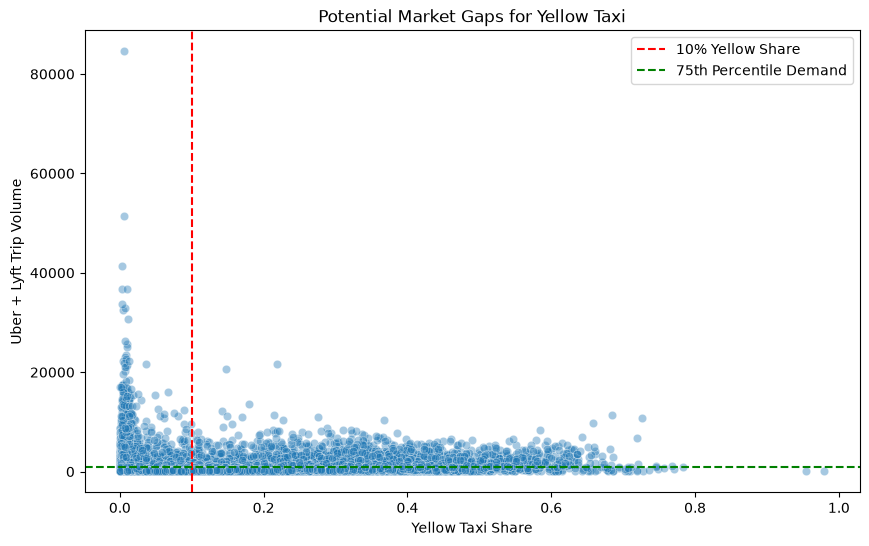

In [16]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=market_filtered,
    x='yellow_share',
    y='rideshare_trips',
    alpha=0.4
)

plt.axvline(
    0.10,
    color='red',
    linestyle='--',
    label='10% Yellow Share'
)

plt.axhline(
    demand_threshold,
    color='green',
    linestyle='--',
    label='75th Percentile Demand'
)

plt.title('Potential Market Gaps for Yellow Taxi')
plt.xlabel('Yellow Taxi Share')
plt.ylabel('Uber + Lyft Trip Volume')

plt.legend()
plt.show()

The market gap analysis identifies several routes with high Uber/Lyft demand but limited Yellow Taxi participation. For example, Route 76 → 76 records more than 84,000 rideshare trips, while Yellow Taxi accounts for only approximately 0.6% of observed trips on that route.

These findings suggest that Yellow Taxi has relatively low market penetration in certain high-demand routes. However, low Yellow Taxi participation does not necessarily indicate unmet demand, as differences in service availability, passenger preferences, and operating conditions may influence market share.

Therefore, these routes should be treated as potential market opportunities requiring further evaluation.

### 4. Evaluate whether these routes are profitable opportunities

In [17]:
# Calculate combined Uber/Lyft efficiency by route
rideshare_efficiency = (
    all_routes_valid[all_routes_valid['service'].isin(['Uber', 'Lyft'])]
    .groupby(['PULocationID', 'DOLocationID'])
    .agg(
        rideshare_fare=('total_fare', 'sum'),
        rideshare_minutes=('total_minutes', 'sum')
    )
    .reset_index()
)

rideshare_efficiency['rideshare_efficiency'] = (
    rideshare_efficiency['rideshare_fare'] /
    rideshare_efficiency['rideshare_minutes']
)

# Rebuild opportunities from the filtered market data
opportunities = market_filtered[
    (market_filtered['rideshare_trips'] >= demand_threshold) &
    (market_filtered['yellow_share'] < 0.10)
].copy()

# Merge efficiency only once
opportunities = opportunities.merge(
    rideshare_efficiency[
        ['PULocationID', 'DOLocationID',
         'rideshare_efficiency']
    ],
    on=['PULocationID', 'DOLocationID'],
    how='left',
    validate='one_to_one'
)

opportunities.head()

,PULocationID,DOLocationID,Lyft,Uber,Yellow Taxi,rideshare_trips,total_trips,yellow_share,rideshare_share,rideshare_efficiency
0,3,3,2048,3889,4,5937,5941,0.000673,0.999327,1.571899
1,3,18,381,620,6,1001,1007,0.005958,0.994042,1.044236
2,3,32,889,1782,9,2671,2680,0.003358,0.996642,1.317409
3,3,51,1373,3120,7,4493,4500,0.001556,0.998444,1.231016
4,3,81,1303,2417,5,3720,3725,0.001342,0.998658,1.312294


In [18]:
opportunities['demand_rank'] = (
    opportunities['rideshare_trips']
    .rank(pct=True)
)

opportunities['efficiency_rank'] = (
    opportunities['rideshare_efficiency']
    .rank(pct=True)
)

# Exploratory opportunity score
opportunities['opportunity_score'] = (
    0.6 * opportunities['demand_rank'] +
    0.4 * opportunities['efficiency_rank']
)

top_opportunities = opportunities.sort_values(
    'opportunity_score',
    ascending=False
)

top_opportunities[
    ['PULocationID', 'DOLocationID',
     'rideshare_trips', 'Yellow Taxi',
     'yellow_share', 'rideshare_efficiency',
     'opportunity_score']
].head(10)

,PULocationID,DOLocationID,rideshare_trips,Yellow Taxi,yellow_share,rideshare_efficiency,opportunity_score
1861,164,138,11888,972,0.075583,1.954212,0.976164
1345,112,112,21005,171,0.008075,1.535615,0.967372
2563,223,223,21026,159,0.007505,1.515336,0.965484
1975,170,138,9639,1063,0.099327,1.982603,0.964832
1093,86,86,17395,65,0.003723,1.516972,0.964051
2492,216,132,14430,433,0.029133,1.557800,0.962488
2656,230,1,8614,875,0.092212,2.335018,0.962227
75,14,14,36717,132,0.003582,1.449278,0.958711
2971,255,256,16718,256,0.015082,1.470354,0.956366
2970,255,255,9794,154,0.015480,1.685452,0.954901


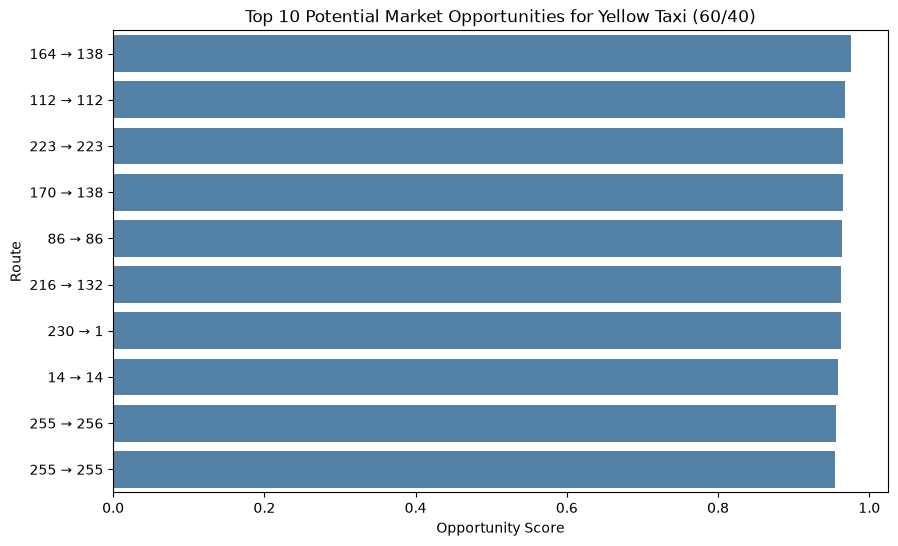

In [19]:
top10_opportunities = top_opportunities.head(10).copy()

top10_opportunities['route'] = (
    top10_opportunities['PULocationID'].astype(str)
    + ' → ' +
    top10_opportunities['DOLocationID'].astype(str)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top10_opportunities,
    x='opportunity_score',
    y='route',
    color='steelblue'
)

plt.title('Top 10 Potential Market Opportunities for Yellow Taxi (60/40)')
plt.xlabel('Opportunity Score')
plt.ylabel('Route')
plt.show()

The opportunity ranking identifies several promising routes based on rideshare demand and fare efficiency. Midtown South → LaGuardia Airport ranks first, with 11,888 rideshare trips, approximately $1.95 in fare revenue per minute, and a Yellow Taxi share of 7.56%.

Other high-ranking routes include local trips within Greenpoint, Steinway, and Far Rockaway, suggesting that potential opportunities are not limited to long-distance or airport transportation.

These findings indicate two potential market segments for Yellow Taxi: airport-related transportation and local neighborhood trips. However, the opportunity score measures relative market attractiveness rather than expected profitability.

The opportunity score is an exploratory ranking tool that combines rideshare demand and fare efficiency. It does not directly estimate Yellow Taxi's potential revenue or profitability.

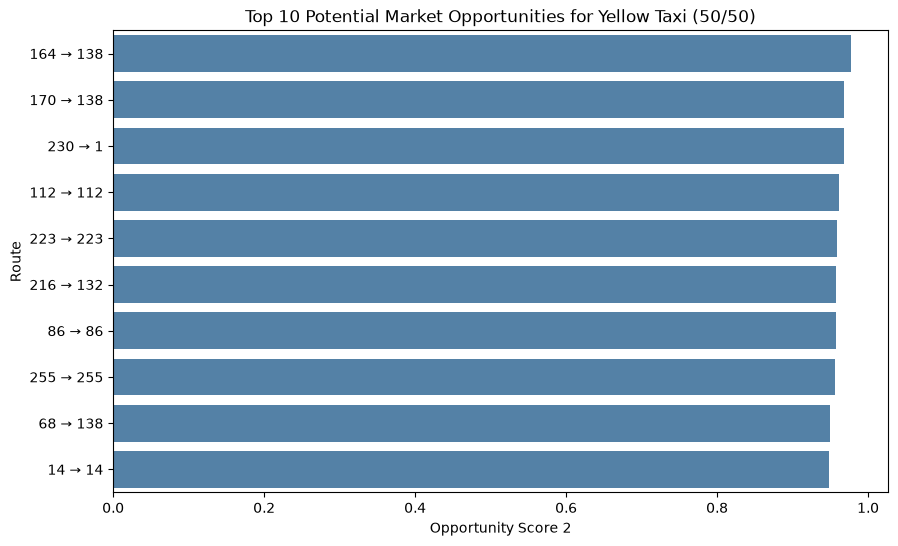

In [20]:
opportunities['opportunity_score 2'] = (
    0.5 * opportunities['demand_rank'] +
    0.5 * opportunities['efficiency_rank']
)

top_opportunities_2 = opportunities.sort_values(
    'opportunity_score 2',
    ascending=False
)

top10_opportunities_2 = top_opportunities_2.head(10).copy()

top10_opportunities_2['route'] = (
    top10_opportunities_2['PULocationID'].astype(str)
    + ' → ' +
    top10_opportunities_2['DOLocationID'].astype(str)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top10_opportunities_2,
    x='opportunity_score 2',
    y='route',
    color='steelblue'
)

plt.title('Top 10 Potential Market Opportunities for Yellow Taxi (50/50)')
plt.xlabel('Opportunity Score 2')
plt.ylabel('Route')
plt.show()

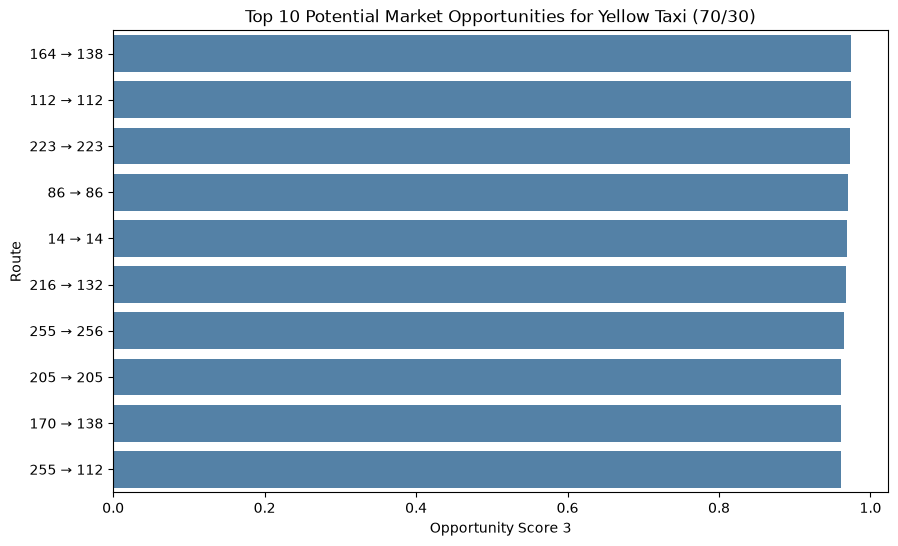

In [21]:
opportunities['opportunity_score 3'] = (
    0.7 * opportunities['demand_rank'] +
    0.3 * opportunities['efficiency_rank']
)

top_opportunities_3 = opportunities.sort_values(
    'opportunity_score 3',
    ascending=False
)

top10_opportunities_3 = top_opportunities_3.head(10).copy()

top10_opportunities_3['route'] = (
    top10_opportunities_3['PULocationID'].astype(str)
    + ' → ' +
    top10_opportunities_3['DOLocationID'].astype(str)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top10_opportunities_3,
    x='opportunity_score 3',
    y='route',
    color='steelblue'
)

plt.title('Top 10 Potential Market Opportunities for Yellow Taxi (70/30)')
plt.xlabel('Opportunity Score 3')
plt.ylabel('Route')
plt.show()

In [22]:
weight_scenarios = {
    '50/50': 0.5,
    '60/40': 0.6,
    '70/30': 0.7
}

ranking_comparison = opportunities[
    ['PULocationID', 'DOLocationID']
].copy()

ranking_comparison['route'] = (
    ranking_comparison['PULocationID'].astype(str)
    + ' → ' +
    ranking_comparison['DOLocationID'].astype(str)
)

for scenario, demand_weight in weight_scenarios.items():
    score = (
        demand_weight * opportunities['demand_rank'] +
        (1 - demand_weight) * opportunities['efficiency_rank']
    )

    ranking_comparison[scenario] = (
        score.rank(ascending=False, method='min')
        .astype(int)
    )

ranking_comparison['rank_range'] = (
    ranking_comparison[['50/50', '60/40', '70/30']].max(axis=1)
    - ranking_comparison[['50/50', '60/40', '70/30']].min(axis=1)
)

ranking_comparison.sort_values('60/40').head(10)

,PULocationID,DOLocationID,route,50/50,60/40,70/30,rank_range
1861,164,138,164 → 138,1,1,1,0
1345,112,112,112 → 112,4,2,2,2
2563,223,223,223 → 223,5,3,3,2
1975,170,138,170 → 138,2,4,9,7
1093,86,86,86 → 86,7,5,4,3
2492,216,132,216 → 132,6,6,6,0
2656,230,1,230 → 1,3,7,15,12
75,14,14,14 → 14,10,8,5,5
2971,255,256,255 → 256,11,9,7,4
2970,255,255,255 → 255,8,10,17,9


The sensitivity analysis evaluates how changes in demand and efficiency weights affect opportunity rankings. Midtown South → LaGuardia Airport consistently ranks first across all three scenarios, indicating that its attractiveness is relatively robust to different weighting assumptions.

Similarly, South Ozone Park → JFK Airport remains in sixth place across all scenarios. In contrast, Times Square → Newark Airport drops from third to fifteenth as the demand weight increases, suggesting that its ranking depends more heavily on revenue efficiency.

These findings suggest that routes with stable rankings may be stronger candidates for further investigation, while routes with large ranking changes require additional evaluation before making business decisions.

### 5. Geographic and Temporal Analysis of Market Opportunities

In [23]:
# Load NYC Taxi Zone Lookup Table
taxi_zones = pd.read_csv("taxi_zone_lookup.csv")

taxi_zones.head()

,LocationID,Borough,Zone,service_zone
0,1,EWR,Newark Airport,EWR
1,2,Queens,Jamaica Bay,Boro Zone
2,3,Bronx,Allerton/Pelham Gardens,Boro Zone
3,4,Manhattan,Alphabet City,Yellow Zone
4,5,Staten Island,Arden Heights,Boro Zone


In [24]:
# Create pickup zone lookup
pickup_zones = taxi_zones[
    ['LocationID', 'Borough', 'Zone']
].rename(columns={
    'LocationID': 'PULocationID',
    'Borough': 'Pickup_Borough',
    'Zone': 'Pickup_Zone'
})

# Create dropoff zone lookup
dropoff_zones = taxi_zones[
    ['LocationID', 'Borough', 'Zone']
].rename(columns={
    'LocationID': 'DOLocationID',
    'Borough': 'Dropoff_Borough',
    'Zone': 'Dropoff_Zone'
})

# Merge zone names with Top 10 opportunities
top10_geo = (
    top10_opportunities
    .merge(
        pickup_zones,
        on='PULocationID',
        how='left',
        validate='many_to_one'
    )
    .merge(
        dropoff_zones,
        on='DOLocationID',
        how='left',
        validate='many_to_one'
    )
)

top10_geo['Route_Name'] = (
    top10_geo['Pickup_Zone'] +
    ' → ' +
    top10_geo['Dropoff_Zone']
)

top10_geo[
    ['Route_Name', 'Pickup_Borough',
     'Dropoff_Borough', 'rideshare_trips',
     'Yellow Taxi', 'yellow_share',
     'rideshare_efficiency', 'opportunity_score']
]

,Route_Name,Pickup_Borough,Dropoff_Borough,rideshare_trips,Yellow Taxi,yellow_share,rideshare_efficiency,opportunity_score
0,Midtown South → LaGuardia Airport,Manhattan,Queens,11888,972,0.075583,1.954212,0.976164
1,Greenpoint → Greenpoint,Brooklyn,Brooklyn,21005,171,0.008075,1.535615,0.967372
2,Steinway → Steinway,Queens,Queens,21026,159,0.007505,1.515336,0.965484
3,Murray Hill → LaGuardia Airport,Manhattan,Queens,9639,1063,0.099327,1.982603,0.964832
4,Far Rockaway → Far Rockaway,Queens,Queens,17395,65,0.003723,1.516972,0.964051
5,South Ozone Park → JFK Airport,Queens,Queens,14430,433,0.029133,1.557800,0.962488
6,Times Sq/Theatre District → Newark Airport,Manhattan,EWR,8614,875,0.092212,2.335018,0.962227
7,Bay Ridge → Bay Ridge,Brooklyn,Brooklyn,36717,132,0.003582,1.449278,0.958711
8,Williamsburg (North Side) → Williamsburg (Sout...,Brooklyn,Brooklyn,16718,256,0.015082,1.470354,0.956366
9,Williamsburg (North Side) → Williamsburg (Nort...,Brooklyn,Brooklyn,9794,154,0.015480,1.685452,0.954901


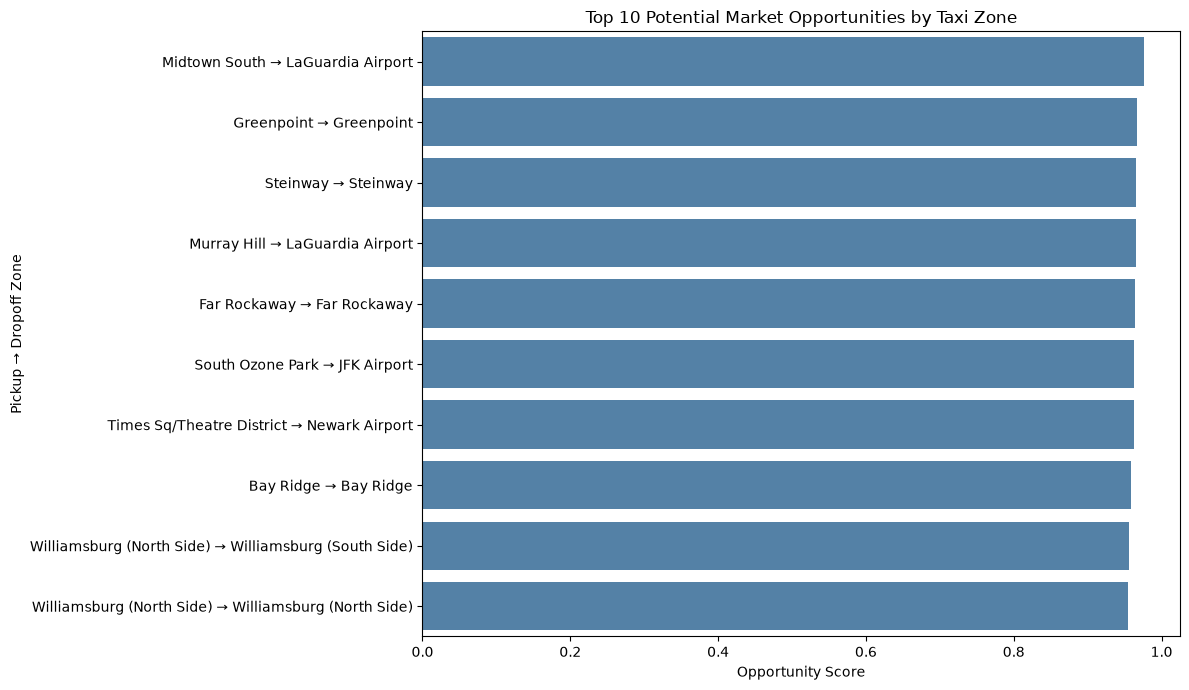

In [25]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top10_geo.sort_values(
        'opportunity_score',
        ascending=False
    ),
    x='opportunity_score',
    y='Route_Name',
    color='steelblue'
)

plt.title('Top 10 Potential Market Opportunities by Taxi Zone')
plt.xlabel('Opportunity Score')
plt.ylabel('Pickup → Dropoff Zone')

plt.tight_layout()
plt.show()

The geographic analysis reveals two major types of potential market opportunities: airport-related routes and local neighborhood trips.

Several high-ranking routes connect Manhattan or Queens to major airports, including LaGuardia, JFK, and Newark. Meanwhile, routes within Greenpoint, Steinway, Far Rockaway, Bay Ridge, and Williamsburg indicate substantial rideshare activity in local neighborhoods where Yellow Taxi participation is relatively low.

These findings suggest that Yellow Taxi could explore different strategies for airport transportation and neighborhood-level mobility rather than applying a single expansion strategy across all routes.

In [26]:
# Select only trips from the Top 10 opportunity routes
top10_keys = top10_geo[
    ['PULocationID', 'DOLocationID']
].drop_duplicates()

# Use the original Uber/Lyft dataset
hourly_trips = uberlyft[
    ['hvfhs_license_num', 'PULocationID',
     'DOLocationID', 'pickup_datetime',
     'trip_miles', 'trip_time',
     'base_passenger_fare']
].merge(
    top10_keys,
    on=['PULocationID', 'DOLocationID'],
    how='inner'
)

# Apply the same cleaning criteria as Part B
hourly_trips['trip_minutes'] = hourly_trips['trip_time'] / 60

hourly_trips['speed_mph'] = (
    hourly_trips['trip_miles'] /
    hourly_trips['trip_minutes'] * 60
)

hourly_trips = hourly_trips[
    (hourly_trips['trip_minutes'] >= 1) &
    (hourly_trips['trip_miles'] > 0) &
    (hourly_trips['base_passenger_fare'] > 0) &
    (hourly_trips['speed_mph'] <= 80) &
    (hourly_trips['hvfhs_license_num'].isin(['HV0003', 'HV0005']))
].copy()

# Extract pickup hour
hourly_trips['pickup_hour'] = (
    hourly_trips['pickup_datetime'].dt.hour
)

hourly_trips['service'] = (
    hourly_trips['hvfhs_license_num'].map({
        'HV0003': 'Uber',
        'HV0005': 'Lyft'
    })
)

hourly_trips.head()

,hvfhs_license_num,PULocationID,DOLocationID,pickup_datetime,trip_miles,trip_time,base_passenger_fare,trip_minutes,speed_mph,pickup_hour,service
0,HV0005,112,112,2026-05-01 00:16:33,0.720,360,10.37,6.000000,7.200000,0,Lyft
1,HV0003,255,256,2026-05-01 00:32:28,1.250,470,8.39,7.833333,9.574468,0,Uber
2,HV0003,112,112,2026-05-01 00:11:28,1.350,434,9.29,7.233333,11.198157,0,Uber
3,HV0003,223,223,2026-05-01 00:13:49,1.120,245,7.58,4.083333,16.457143,0,Uber
4,HV0005,223,223,2026-05-01 00:35:09,0.619,352,6.32,5.866667,6.330682,0,Lyft


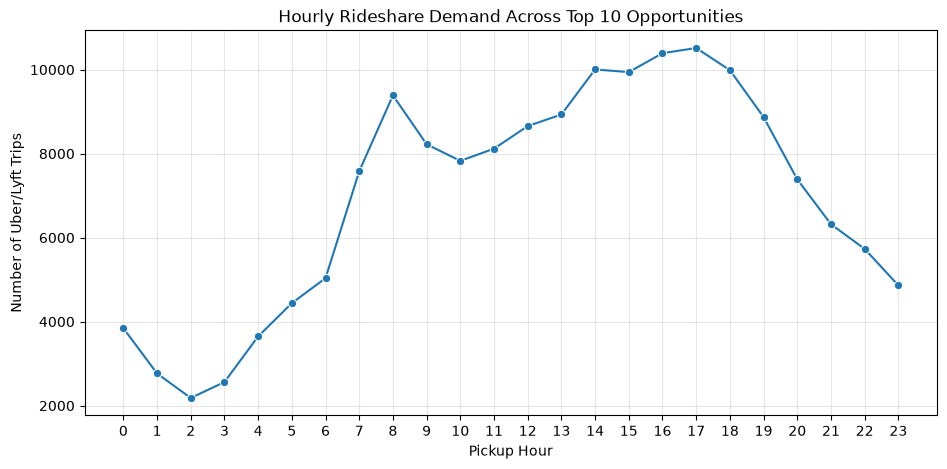

In [27]:
hourly_demand = (
    hourly_trips.groupby('pickup_hour')
    .size()
    .reindex(range(24), fill_value=0)
    .reset_index(name='trip_count')
)

plt.figure(figsize=(11, 5))

sns.lineplot(
    data=hourly_demand,
    x='pickup_hour',
    y='trip_count',
    marker='o'
)

plt.title('Hourly Rideshare Demand Across Top 10 Opportunities')
plt.xlabel('Pickup Hour')
plt.ylabel('Number of Uber/Lyft Trips')
plt.xticks(range(24))
plt.grid(alpha=0.3)

plt.show()

In [31]:
hourly_demand.sort_values(
    'trip_count',
    ascending=False
).head(5)

,pickup_hour,trip_count
17,17,10516
16,16,10392
14,14,10005
18,18,9988
15,15,9942


The hourly demand analysis examines how Uber and Lyft trip volumes change throughout the day across the top 10 opportunity routes.

Understanding these temporal patterns is important because high monthly demand does not necessarily imply consistently high demand throughout the day. Identifying periods of concentrated activity can help Yellow Taxi evaluate targeted fleet allocation rather than increasing vehicle availability uniformly across all hours.

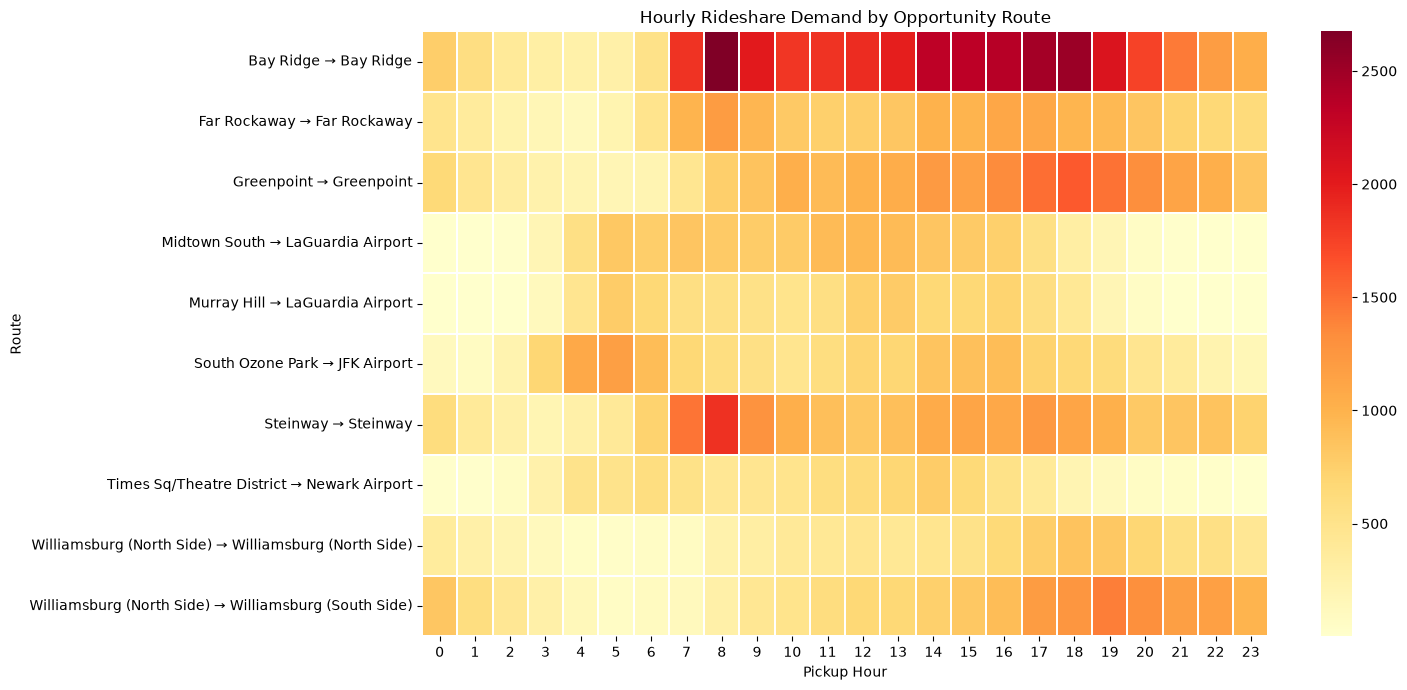

In [28]:
# Add zone names
hourly_trips = (
    hourly_trips
    .merge(
        top10_geo[
            ['PULocationID', 'DOLocationID', 'Route_Name']
        ].drop_duplicates(),
        on=['PULocationID', 'DOLocationID'],
        how='left'
    )
)

route_hour = (
    hourly_trips
    .groupby(['Route_Name', 'pickup_hour'])
    .size()
    .reset_index(name='trip_count')
)

heatmap_data = route_hour.pivot_table(
    index='Route_Name',
    columns='pickup_hour',
    values='trip_count',
    fill_value=0
)

heatmap_data = heatmap_data.reindex(
    columns=range(24),
    fill_value=0
)

plt.figure(figsize=(15, 7))

sns.heatmap(
    heatmap_data,
    cmap='YlOrRd',
    linewidths=0.3
)

plt.title('Hourly Rideshare Demand by Opportunity Route')
plt.xlabel('Pickup Hour')
plt.ylabel('Route')

plt.tight_layout()
plt.show()

The route-level heatmap compares absolute hourly rideshare demand across the top 10 opportunity routes. It helps identify which routes generate the largest number of trips during specific periods.

This analysis is particularly useful for evaluating where additional Yellow Taxi availability may have the greatest potential impact. However, high rideshare demand alone does not guarantee that additional Yellow Taxi supply would be economically beneficial.

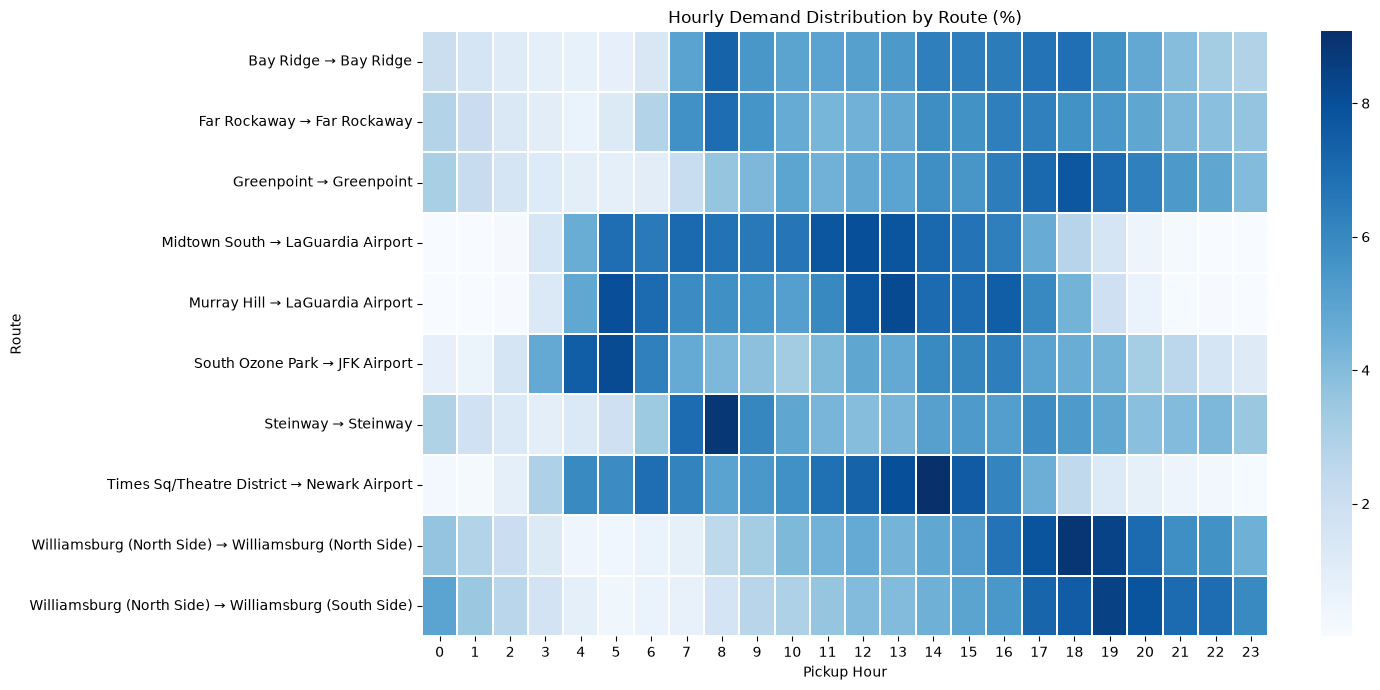

In [29]:
# Normalize each route by its total trips
heatmap_pct = heatmap_data.div(
    heatmap_data.sum(axis=1),
    axis=0
) * 100

plt.figure(figsize=(15, 7))

sns.heatmap(
    heatmap_pct,
    cmap='Blues',
    linewidths=0.3
)

plt.title('Hourly Demand Distribution by Route (%)')
plt.xlabel('Pickup Hour')
plt.ylabel('Route')

plt.tight_layout()
plt.show()

The normalized heatmap shows the percentage of each route's daily trips occurring during each hour. Unlike the absolute-demand heatmap, this visualization allows comparison of hourly demand patterns across routes with different total trip volumes.

By identifying whether demand is concentrated during particular hours or distributed throughout the day, Yellow Taxi can develop route-specific scheduling strategies. Routes with concentrated demand may benefit from targeted service availability, while routes with more consistent demand may require different operating approaches.

In [30]:
peak_hours = (
    route_hour
    .sort_values(
        ['Route_Name', 'trip_count'],
        ascending=[True, False]
    )
    .drop_duplicates('Route_Name')
    .rename(columns={
        'pickup_hour': 'Peak_Hour',
        'trip_count': 'Peak_Hour_Trips'
    })
)

final_opportunities = top10_geo.merge(
    peak_hours[
        ['Route_Name', 'Peak_Hour', 'Peak_Hour_Trips']
    ],
    on='Route_Name',
    how='left'
)

final_opportunities[
    ['Route_Name', 'rideshare_trips',
     'yellow_share', 'rideshare_efficiency',
     'opportunity_score', 'Peak_Hour',
     'Peak_Hour_Trips']
].sort_values(
    'opportunity_score',
    ascending=False
)

,Route_Name,rideshare_trips,yellow_share,rideshare_efficiency,opportunity_score,Peak_Hour,Peak_Hour_Trips
0,Midtown South → LaGuardia Airport,11888,0.075583,1.954212,0.976164,12,952
1,Greenpoint → Greenpoint,21005,0.008075,1.535615,0.967372,18,1617
2,Steinway → Steinway,21026,0.007505,1.515336,0.965484,8,1853
3,Murray Hill → LaGuardia Airport,9639,0.099327,1.982603,0.964832,13,789
4,Far Rockaway → Far Rockaway,17395,0.003723,1.516972,0.964051,8,1204
5,South Ozone Park → JFK Airport,14430,0.029133,1.557800,0.962488,5,1172
6,Times Sq/Theatre District → Newark Airport,8614,0.092212,2.335018,0.962227,14,782
7,Bay Ridge → Bay Ridge,36717,0.003582,1.449278,0.958711,8,2675
8,Williamsburg (North Side) → Williamsburg (Sout...,16718,0.015082,1.470354,0.956366,19,1412
9,Williamsburg (North Side) → Williamsburg (Nort...,9794,0.015480,1.685452,0.954901,18,867


### 6. Business Recommendations and Conclusion

The analysis identifies several potential market opportunities for Yellow Taxi by combining rideshare demand, revenue efficiency, and market presence. The results highlight two major market segments: airport-related transportation and local neighborhood trips.

**First, Yellow Taxi should prioritize further evaluation of airport-related routes.** Midtown South → LaGuardia Airport consistently ranks first across different opportunity score assumptions, suggesting relatively strong market potential. However, airport pickup regulations, vehicle availability, and waiting times must be considered before expanding service.

**Second, Yellow Taxi should explore opportunities in local neighborhoods.** Routes within Greenpoint, Steinway, Far Rockaway, and Bay Ridge show substantial Uber/Lyft activity but relatively low Yellow Taxi participation. Improving ride-hailing accessibility and vehicle availability in these areas may help Yellow Taxi compete for additional demand.

**Third, Yellow Taxi should consider time-based fleet allocation.** Hourly demand analysis can help identify when additional service may be most valuable. Instead of increasing supply uniformly, Yellow Taxi could evaluate targeted scheduling strategies based on route-specific demand patterns.

Overall, the findings suggest that combining market demand, revenue efficiency, and geographic and temporal patterns provides a more comprehensive approach to identifying potential market opportunities than relying on revenue efficiency alone.

However, these findings represent potential opportunities rather than confirmed profitability. Further evaluation of operating costs, regulatory constraints, passenger preferences, and vehicle availability is necessary before implementing expansion strategies.